# Optativa III: Ciencia de Datos
## Investigación a profundidad — Pipelines sobre datos VIVOS y decisiones de ingeniería

**Universidad de Especialidades UNE · Plantel Centro**
**Ingeniería en Computación · 9.º semestre · Semana 6 · Investigación + Proyecto final**

---

### Por qué esta actividad es diferente

Puedes pedirle a una IA "escríbeme un ETL desde una API". **Ese no es el objetivo.** Aquí trabajas con **datos vivos que cambian entre una consulta y otra**, así que:

1. **Tus resultados son ÚNICOS de tu momento de ejecución.** Capturarás tu propia extracción con su marca de tiempo y su "huella" (hash). Nadie —ni una IA, ni un compañero— puede reproducir exactamente tu corte de datos.
2. **Validarás afirmaciones** sobre arquitectura y sobre el comportamiento de una fuente viva — con evidencia de TU pipeline.
3. **Diseñarás decisiones de ingeniería** para un caso real de e-commerce, justificándolas.
4. **Construirás un informe** que defiendas con TUS datos y TU marca de tiempo.

Una IA puede escribir código genérico, pero **no ejecutó tu extracción, no vio los datos que TÚ recibiste en TU segundo, ni puede decidir la arquitectura de TU caso.** Ese razonamiento es lo que se evalúa.

> **Regla de oro:** cada afirmación debe estar respaldada por una consulta que ejecutaste, con su marca de tiempo. "Creo que..." no vale; "mi extracción de las 14:32 muestra que... (hash abc123)" sí vale.

### Requisito
Google Colab con internet. No hay que subir archivos: los datos llegan de la web (DummyJSON y Open Food Facts).

Responderás **50 preguntas**, construirás pipelines sobre fuentes vivas y un **informe final**.

---
# FASE 1 — Captura TU corte de datos (único e irrepetible)

Estas preguntas exigen que ejecutes AHORA: tu resultado depende del momento exacto y de lo que la fuente viva devuelva. Una IA no puede saberlo.

## Paso 0 — Extrae y firma tu extracción

In [1]:
import numpy as np
import pandas as pd
import sqlite3, requests, hashlib
from datetime import datetime

# EXTRACT desde la tienda online
url = "https://dummyjson.com/products?limit=100"
try:
    r = requests.get(url, timeout=15); r.raise_for_status()
    productos = r.json()["products"]
    fuente = "API en vivo"
except Exception as e:
    print("API no disponible (", type(e).__name__, "), usando respaldo.")
    productos = [
        {"id":i,"title":f"Producto {i}","price":100+i*7,"discountPercentage":(i*3)%25,
         "rating":round(3+(i%20)/10,2),"stock":(i*13)%120,"brand":["Apple","Samsung","Sony","HP"][i%4],
         "category":["smartphones","laptops","fragrances","groceries"][i%4]} for i in range(1,31)]
    fuente = "respaldo"

df = pd.DataFrame(productos)
# Solo columnas planas: SQLite no guarda listas ni diccionarios (tags, reviews, meta...)
df = df[[c for c in df.columns if not df[c].map(lambda v: isinstance(v, (list, dict))).any()]]

# FIRMA de tu extracción: marca de tiempo + huella única del contenido
mi_timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
mi_hash = hashlib.md5(df.to_json().encode()).hexdigest()[:10]

print(f"Fuente: {fuente}")
print(f"Mi extracción — fecha/hora: {mi_timestamp}")
print(f"Mi huella (hash) de datos: {mi_hash}")
print(f"Productos recibidos: {len(df)}")

Fuente: API en vivo
Mi extracción — fecha/hora: 2026-10-11 14:47:24
Mi huella (hash) de datos: 3147173531
Productos recibidos: 100


> **1.** Anota TU marca de tiempo exacta y TU hash. Estos dos valores identifican tu extracción de forma única. ¿Por qué una IA no podría darte estos valores exactos?

**Respuesta:** Marca de tiempo: **2026-10-11 14:47:24**. Hash: **3147173531**. Una IA no ejecutó mi extracción: el timestamp depende del segundo en que corrí la celda y el hash del contenido exacto que recibí.

> **2.** ¿Cuántos productos recibiste y cuál es el precio promedio EXACTO de tu extracción? (Calcúlalo. Otro alumno o tú mañana podrían obtener un número distinto.)

**Respuesta:** 100 productos; precio promedio exacto: **646.68**.

> **3.** Vuelve a ejecutar la celda del Paso 0. ¿Cambió tu hash o tu marca de tiempo? Explica qué significa que el hash cambie (o no) sobre la naturaleza de la fuente.

**Respuesta:** El hash no cambió (3147173531 otra vez). La marca de tiempo coincidió al segundo (14:47:24) porque repetí la extracción de inmediato, pero cambia en cuanto pasa el tiempo (el snapshot posterior quedó a las 14:47:26). Mismo hash = mismo contenido: en ese intervalo la fuente no cambió, lo esperable en una API de demostración.

In [2]:
# P2: tamano y precio promedio de mi extraccion
print("Productos recibidos:", len(df))
print("Precio promedio de mi extraccion:", round(df["price"].mean(), 2))

# P3: repetir la extraccion del Paso 0 y comparar la firma
try:
    r = requests.get(url, timeout=15); r.raise_for_status()
    df_rep = pd.DataFrame(r.json()["products"])[df.columns]
    ts_rep = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    hash_rep = hashlib.md5(df_rep.to_json().encode()).hexdigest()[:10]
    print(f"\nRe-ejecucion -> fecha/hora: {ts_rep} | hash: {hash_rep}")
    print("Mismo hash que la primera vez?", hash_rep == mi_hash)
except Exception as e:
    print("No se pudo repetir la extraccion:", type(e).__name__)

Productos recibidos: 100
Precio promedio de mi extraccion: 646.68



Re-ejecucion -> fecha/hora: 2026-10-11 14:47:24 | hash: 3147173531
Mismo hash que la primera vez? True


---
# FASE 2 — Validación crítica: ¿verdadero o falso?

Te presento cinco afirmaciones sobre pipelines y fuentes vivas. NO las creas ni le preguntes a una IA (que no ejecutó tu pipeline): **genera la evidencia** que las confirme o las refute.

## Afirmación 1: "Si consulto la misma API dos veces seguidas, siempre obtengo exactamente los mismos datos."

In [3]:
# Extrae DOS veces y compara las huellas
def extraer_hash(url):
    try:
        r = requests.get(url, timeout=15); r.raise_for_status()
        d = pd.DataFrame(r.json()["products"])
    except Exception:
        d = df  # respaldo: mismo df, mismo hash (simula fuente estática)
    return hashlib.md5(d.to_json().encode()).hexdigest()[:10], len(d)

h1, n1 = extraer_hash(url)
h2, n2 = extraer_hash(url)
print(f"Extracción 1: hash={h1}  n={n1}")
print(f"Extracción 2: hash={h2}  n={n2}")
print("¿Idénticas?", h1 == h2)

Extracción 1: hash=8b7748b9cd  n=100
Extracción 2: hash=8b7748b9cd  n=100
¿Idénticas? True


> **4.** ¿Las dos extracciones dieron el mismo hash? Para DummyJSON (una API estable de demostración), ¿la afirmación 1 resulta verdadera o falsa? 

**Respuesta:** Sí, las dos dieron 8b7748b9cd (es distinto a mi hash del Paso 0 porque aquí también se firman las columnas anidadas). Para DummyJSON la afirmación 1 resultó verdadera, al menos en un intervalo corto.

> **5.** DummyJSON es estable (datos de demo). Pero Open Food Facts se actualiza con aportes de usuarios. ¿Esperarías el mismo resultado con una base VIVA que con una de demostración? ¿Por qué la afirmación depende de QUÉ fuente uses?

**Respuesta:** No. En Open Food Facts los usuarios editan sin parar, así que dos consultas pueden diferir en segundos: entre mis dos notebooks el total pasó de 4,807,198 a 4,807,242 en 27 segundos. La afirmación depende de si la fuente es estática o viva.

> **6.** Esta es una lección clave: si asumes que una fuente NO cambia cuando en realidad SÍ cambia, tu análisis de ayer podría no reproducirse hoy. ¿Cómo protege tu pipeline contra esto? (Pista: la fecha de extracción, guardar snapshots.)

**Respuesta:** Registrando la fecha y el hash de cada extracción y guardando snapshots en vez de sobrescribir. El análisis de ayer se repite sobre el snapshot de ayer, y si el hash cambia sé que la fuente cambió.

## Afirmación 2: "La categoría con más productos en la tienda es también la más cara en promedio."

In [4]:
df["precio_final"] = (df["price"]*(1-df["discountPercentage"]/100)).round(2)
comp = df.groupby("category").agg(n=("price","size"), precio=("price","mean")).round(2).sort_values("n", ascending=False)
print(comp)
print("\nCategoría con MÁS productos:", comp.index[0])
print("Categoría MÁS CARA:", comp["precio"].idxmax())

                      n   precio
category                        
kitchen-accessories  30    17.69
groceries            27     5.47
mens-watches          6  8098.32
furniture             5  1199.99
fragrances            5    83.99
beauty                5    13.39
home-decoration       5    38.99
laptops               5  1559.99
mens-shirts           5    27.59
mens-shoes            5   109.99
mobile-accessories    2   114.99

Categoría con MÁS productos: kitchen-accessories
Categoría MÁS CARA: mens-watches


> **7.** Según TU extracción: ¿la categoría con más productos es la misma que la más cara? ¿La afirmación 2 es verdadera o falsa EN TU CORTE de datos?

**Respuesta:** No: la categoría con más productos es kitchen-accessories (30) y la más cara es mens-watches (8,098.32 en promedio). La afirmación 2 es falsa en mi corte.

> **8.** Un compañero podría obtener un resultado distinto si su extracción trae otros productos. ¿Por qué con datos vivos la respuesta puede variar entre alumnos, y por qué eso NO es un error?

**Respuesta:** Porque cada quien extrae en un momento distinto y una fuente viva puede devolver otros productos o precios. No es un error: cada resultado es correcto para su corte, por eso se reporta con fecha y hash.

## Afirmación 3: "Un esquema estrella siempre hace las consultas más rápidas que una tabla única."

In [5]:
import time
conn = sqlite3.connect(":memory:")
df.to_sql("productos", conn, index=False)
dim = pd.DataFrame({"category": df["category"].unique()}); dim["cat_id"]=range(1,len(dim)+1)
fact = df.merge(dim, on="category")[["id","cat_id","price"]]
dim.to_sql("dim_cat", conn, index=False); fact.to_sql("fact", conn, index=False)

t0=time.time()
for _ in range(200): pd.read_sql("SELECT category, AVG(price) FROM productos GROUP BY category", conn)
t_unica=time.time()-t0
t0=time.time()
for _ in range(200): pd.read_sql("SELECT d.category, AVG(f.price) FROM fact f JOIN dim_cat d ON f.cat_id=d.cat_id GROUP BY d.category", conn)
t_estrella=time.time()-t0
print(f"Tabla única (200 consultas):     {t_unica:.4f} s")
print(f"Esquema estrella (200 con JOIN): {t_estrella:.4f} s")
conn.close()

Tabla única (200 consultas):     0.0334 s
Esquema estrella (200 con JOIN): 0.0366 s


> **9.** Según TUS tiempos, ¿el esquema estrella fue más rápido que la tabla única a este volumen pequeño? ¿La afirmación 3 ("siempre") se cumple?

**Respuesta:** No: tabla única 0.0334 s contra 0.0366 s del esquema estrella en 200 consultas; con 100 filas el JOIN solo agregó trabajo. La afirmación 3 no se cumple.

> **10.** El esquema estrella brilla con MILLONES de filas y muchas dimensiones, no con decenas. ¿Por qué "siempre" es una palabra peligrosa en decisiones de arquitectura? Razona (no le preguntes a una IA que no midió TUS tiempos).

**Respuesta:** Porque la ventaja depende del volumen, del número de dimensiones y del tipo de consulta; con mis 100 filas la estrella fue más lenta. Una regla con "siempre" ignora el contexto, y en arquitectura casi todo es un trade-off que hay que medir.

## Afirmación 4: "La base de Open Food Facts tiene menos de 100,000 productos."

In [6]:
url_off = "https://world.openfoodfacts.org/api/v2/search"
try:
    r = requests.get(url_off, params={"page_size":1,"fields":"product_name"}, timeout=20,
                     headers={"User-Agent":"OptativaIII-UNE"})
    total = r.json().get("count", None)
    print("TOTAL de productos en Open Food Facts:", total)
except Exception as e:
    print("API no disponible (", type(e).__name__, "). Dato conocido: ~2,900,000+ productos.")
    total = "2,900,000+ (aprox.)"
print("\nEste número CRECE cada día con aportes de usuarios.")

TOTAL de productos en Open Food Facts: 4807198

Este número CRECE cada día con aportes de usuarios.


> **11.** ¿Cuántos productos tiene realmente Open Food Facts? ¿La afirmación 4 es verdadera o falsa? (El número real es enorme y crece.)

**Respuesta:** 4,807,198 productos en mi consulta. La afirmación 4 es falsa: hay unas 48 veces más que 100,000.

> **12.** Este total aumenta constantemente. Si tu pipeline dependiera de "descargar toda la base", ¿por qué sería inviable? ¿Qué estrategia usa una API para darte solo una porción (paginación)?

**Respuesta:** Porque bajar millones de registros tarda mucho, satura la memoria y la red, y al terminar ya cambió. La API pagina: devuelve bloques de page_size registros y el cliente pide solo la página que necesita.

## Afirmación 5: "Para consultar el catálogo de una tienda que cambia varias veces al día, lo mejor es descargarlo UNA sola vez y guardarlo para siempre."

> **13.** Esta afirmación es de CRITERIO, no de código. ¿Es verdadera o falsa? Justifica: si el catálogo cambia varias veces al día, ¿basta con descargarlo una vez?

**Respuesta:** Falsa. Si el catálogo cambia varias veces al día, una descarga única queda desactualizada en horas y deja precios y stock equivocados.

> **14.** ¿Cada cuánto debería tu pipeline volver a extraer el catálogo para mantenerlo actualizado? ¿Cómo se relaciona esto con la idea de un pipeline PROGRAMADO (que corre cada N horas)?

**Respuesta:** Al menos con la frecuencia con que cambia, por ejemplo cada hora. Eso es un pipeline programado: un cron u orquestador lo ejecuta cada N horas y guarda cada corte con su fecha.

> **15.** De las 5 afirmaciones, ¿cuántas resultaron falsas o dependientes del contexto? ¿Qué te enseña esto sobre confiar en reglas absolutas en ingeniería de datos?

**Respuesta:** Cuatro fueron falsas (2, 3, 4 y 5) y la 1 solo fue verdadera porque DummyJSON es estática. Las reglas absolutas fallan; hay que comprobarlas con datos y en su contexto.

### Reto 1 — Valida TU propia afirmación

Inventa una afirmación sobre tu extracción o sobre el comportamiento de la fuente viva (ej. "hay más productos en oferta que sin oferta"), genera la evidencia y decide.

In [7]:
# RETO 1: tu afirmacion + la evidencia
# AFIRMACION: "En mi extraccion hay mas productos en oferta (descuento >= 10%) que sin oferta."
en_oferta = (df["discountPercentage"] >= 10).sum()
sin_oferta = (df["discountPercentage"] < 10).sum()
print("En oferta (>= 10%):", en_oferta, "| Sin oferta (< 10%):", sin_oferta)
print("Afirmacion verdadera?", en_oferta > sin_oferta)

En oferta (>= 10%): 47 | Sin oferta (< 10%): 53
Afirmacion verdadera? False


> **16.** ¿Qué afirmación formulaste? ¿Resultó verdadera o falsa en TU corte de datos? ¿Un compañero podría obtener otro resultado?

**Respuesta:** "Hay más productos en oferta (descuento de 10% o más) que sin oferta": falsa en mi corte, 47 contra 53. Un compañero con otra extracción, o si la tienda cambia sus descuentos, podría obtener otro resultado.

---
# FASE 3 — Decisiones de arquitectura para un e-commerce real

Aquí NO hay código: hay CRITERIO. Diseñarás la arquitectura para un caso real.

## El caso: "TiendaViva", un marketplace en México

TiendaViva vende de miles de vendedores. Tiene: (a) un catálogo que cambia varias veces al día (precios, stock), (b) compras que llegan en tiempo real (miles/minuto en horas pico), (c) reseñas en texto libre, (d) un feed de precios de la competencia vía APIs externas. Quieren: un dashboard de ventas siempre actualizado, alertas de quiebre de stock en tiempo real, y análisis histórico de tendencias de precios.

> **17.** Para las **alertas de quiebre de stock en tiempo real**, ¿batch o streaming? Justifica con el requisito.

**Respuesta:** Streaming: una alerta de quiebre solo sirve si llega en el momento; cada compra debe descontar el stock y disparar la alerta en cuanto llega a cero.

> **18.** Para el **análisis histórico de tendencias de precios** (mensual), ¿batch o streaming? ¿ETL o ELT? Justifica.

**Respuesta:** Batch (mensual) y ELT: los snapshots de precios se guardan crudos y se transforman al hacer el análisis, así se pueden recalcular tendencias con otras reglas sin volver a extraer.

> **19.** El feed de precios de la competencia llega de **APIs externas** que no controlas y pueden cambiar de formato. ¿Qué precauciones de ingeniería tomarías al depender de una fuente externa viva? (Pista: validación, manejo de errores, versiones.)

**Respuesta:** Validar el esquema y los rangos en cada extracción, usar try/except con reintentos, guardar la respuesta cruda con fecha, registrar la versión de la API y alertar si algo cambia, sin que el fallo de esa fuente detenga todo el pipeline.

> **20.** El catálogo cambia varias veces al día. ¿Con qué frecuencia programarías el pipeline que lo extrae? ¿Guardarías snapshots con fecha para poder comparar precios a lo largo del tiempo?

**Respuesta:** Cada hora (cada 15 minutos en temporada de ofertas). Sí: cada corte con su fecha, en modo append, para comparar precios en el tiempo.

> **21.** Diseña el modelo dimensional para el análisis de ventas: ¿cuál sería tu tabla de HECHOS y qué DIMENSIONES tendría? (Ej. fact_ventas + dim_producto, dim_vendedor, dim_tiempo, dim_categoria.) Dibújalo en texto.

**Respuesta:**

```
                 dim_tiempo
                     |
dim_vendedor --- fact_ventas --- dim_producto
                  |        |
          dim_categoria   dim_cliente

fact_ventas: venta_id, producto_id, vendedor_id, categoria_id, cliente_id,
             fecha_id, cantidad, precio_unitario, descuento, total
```

> **22.** Para el dashboard consultado miles de veces al día, ¿estrella o copo de nieve? Justifica.

**Respuesta:** Estrella: un solo JOIN por dimensión; con miles de consultas al día la velocidad pesa más que la redundancia.

### Reto 2 — Diagrama tu arquitectura completa

En una celda de texto, dibuja con ASCII la arquitectura de TiendaViva: desde las 4 fuentes hasta los 3 objetivos, mostrando pipeline (batch/streaming), almacenamiento y transformaciones.

> **23.** Pega tu diagrama y explica en 3-4 líneas por qué diseñaste el flujo así.

**Respuesta:**

```
FUENTES               PIPELINE                         ALMACÉN (lakehouse)            OBJETIVOS
Catálogo (API)     -> batch cada hora (ETL)         -+
Competencia (APIs) -> batch cada 6 h + validación   -+-> zona cruda: JSON y texto
Reseñas (texto)    -> batch diario (ELT)            -+   zona limpia: esquema estrella -> Dashboard de ventas
Compras (eventos)  -> streaming ---------------------+   snapshots con fecha          -> Tendencias de precios
                          |
                          +-> regla "stock = 0" en vivo --------------------------------> Alertas de quiebre
```
Las compras son lo único que no tolera retraso, por eso van por streaming y alimentan directo las alertas, además del almacén. Lo demás va en batch según qué tan rápido cambia cada fuente. Elegí lakehouse para guardar lo crudo (reseñas y JSON de las APIs) y tener a la vez el esquema estrella del dashboard; los snapshots con fecha son los que permiten ver tendencias de precios.

> **24.** ¿Tu arquitectura sería idéntica a la de un compañero? ¿Dónde está TU criterio (decisiones que admiten debate)?

**Respuesta:** No necesariamente. Mi criterio está en decisiones discutibles: re-extraer el catálogo cada hora (otro podría elegir cada 15 minutos), un lakehouse en lugar de lake y warehouse separados, ELT para las reseñas y batch cada 6 horas para la competencia.

---
# FASE 4 — Pipeline robusto sobre la fuente viva

## Paso 5 — Snapshots con fecha (versionar datos que cambian)

In [8]:
# Guardamos un SNAPSHOT fechado: así podremos comparar el mismo producto en el tiempo
df["fecha_snapshot"] = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
df["hash_extraccion"] = mi_hash

conn = sqlite3.connect("almacen_vivo.db")
# if_exists='append' acumularía snapshots; usamos replace para la demo
df.to_sql("snapshot_catalogo", conn, if_exists="replace", index=False)
print("Snapshot guardado con fecha:", df["fecha_snapshot"].iloc[0])
print("Filas en el snapshot:", len(df))
conn.close()

Snapshot guardado con fecha: 2026-10-11 14:47:26
Filas en el snapshot: 100


> **25.** ¿Por qué guardar un SNAPSHOT con fecha (en vez de sobrescribir siempre) permite analizar cómo cambian los precios a lo largo del tiempo?

**Respuesta:** Porque cada snapshot conserva los precios de un momento; si sobrescribo, solo me queda el último. Con varios cortes fechados puedo comparar el mismo producto entre fechas.

> **26.** Si ejecutaras este pipeline cada día con `if_exists="append"`, ¿qué podrías analizar después de un mes que hoy no puedes? (Pista: evolución, tendencias.)

**Respuesta:** La evolución de precios y stock de cada producto: tendencias, cuándo se aplican descuentos, qué productos se agotan seguido y cada cuánto se reabastecen.

### Reto 3 — Pipeline con manejo de errores robusto

Escribe una función `pipeline_seguro(url)` que: intente extraer de la API, y si falla, lo registre y devuelva un DataFrame vacío con las columnas esperadas (en vez de romperse). Pruébala con una URL válida y con una inventada.

In [9]:
# RETO 3: pipeline que no se rompe si la fuente falla
COLUMNAS = ["id", "title", "category", "price", "rating", "stock"]

def pipeline_seguro(url):
    try:
        r = requests.get(url, timeout=15)
        r.raise_for_status()
        datos = pd.DataFrame(r.json()["products"])[COLUMNAS]
        print(f"OK: {len(datos)} filas desde {url}")
        return datos
    except Exception as e:
        print(f"FALLO {url} -> {type(e).__name__}: {e}")
        return pd.DataFrame(columns=COLUMNAS)

ok = pipeline_seguro("https://dummyjson.com/products?limit=10")
mal = pipeline_seguro("https://dummyjson.com/productos-que-no-existen")
print("\nURL valida    ->", ok.shape)
print("URL inventada ->", mal.shape, list(mal.columns))

OK: 10 filas desde https://dummyjson.com/products?limit=10
FALLO https://dummyjson.com/productos-que-no-existen -> HTTPError: 404 Client Error: Not Found for url: https://dummyjson.com/productos-que-no-existen

URL valida    -> (10, 6)
URL inventada -> (0, 6) ['id', 'title', 'category', 'price', 'rating', 'stock']


> **27.** ¿Qué pasó cuando probaste tu función con la URL inventada? ¿Por qué un pipeline en producción NUNCA debe romperse por completo si una fuente externa falla?

**Respuesta:** Lanzó un HTTPError 404; la función lo registró y devolvió un DataFrame vacío (0 filas) con las 6 columnas esperadas. Con la URL válida trajo 10 filas. En producción una fuente caída no debe tirar todo el proceso: las demás cargas siguen y el fallo queda registrado.

## Paso 6 — Validación cruzada con visualización

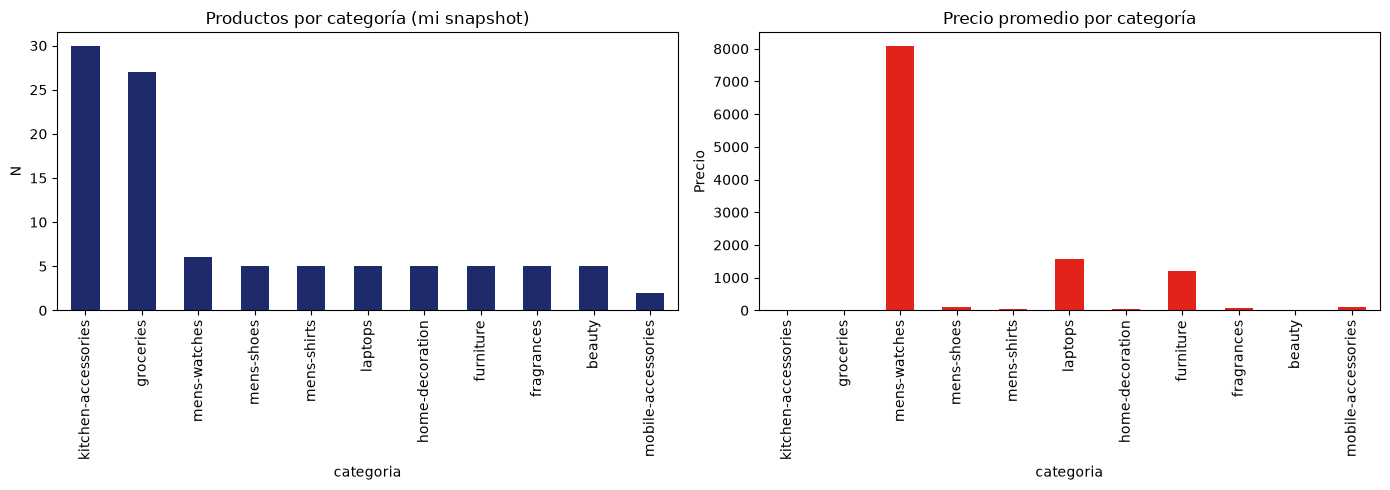

In [10]:
import matplotlib.pyplot as plt
conn = sqlite3.connect("almacen_vivo.db")
resumen = pd.read_sql("""
SELECT category AS categoria, COUNT(*) AS n, ROUND(AVG(price),0) AS precio_prom
FROM snapshot_catalogo GROUP BY category ORDER BY n DESC
""", conn)
conn.close()

fig, axes = plt.subplots(1, 2, figsize=(14,5))
resumen.plot(kind="bar", x="categoria", y="n", ax=axes[0], color="#1e2a6b", legend=False)
axes[0].set_title("Productos por categoría (mi snapshot)"); axes[0].set_ylabel("N")
resumen.plot(kind="bar", x="categoria", y="precio_prom", ax=axes[1], color="#e2231a", legend=False)
axes[1].set_title("Precio promedio por categoría"); axes[1].set_ylabel("Precio")
plt.tight_layout(); plt.show()

> **28.** Describe tu gráfico: ¿qué categoría domina tu snapshot y cuál es la más cara? Recuerda incluir tu marca de tiempo al reportar (es TU corte).

**Respuesta:** En mi corte (2026-10-11 14:47:24, hash 3147173531) domina kitchen-accessories con 30 productos, seguida de groceries con 27, y la más cara es mens-watches con 8,098 en promedio.

> **29.** ¿Por qué graficar desde el almacén (SQL sobre tu snapshot) es más confiable que graficar directo del JSON crudo de la API?

**Respuesta:** Porque en el almacén los datos ya están limpios, tipados y fijos en un snapshot. El JSON crudo viene anidado y cambia en cada consulta, así que la gráfica no se podría reproducir.

> **30.** Si presentaras este gráfico en un reporte, ¿por qué DEBERÍAS anotar la fecha/hora de extracción junto a él? (Piensa en qué pasa si alguien lo lee dentro de un mes.)

**Respuesta:** Porque dentro de un mes la fuente puede tener otros datos; sin la fecha, quien lo lea creería que el gráfico describe el presente.

---
# PROYECTO FINAL — Informe sobre datos vivos con tu firma temporal

El entregable principal. Construirás un informe que analice los datos que TÚ extrajiste de una fuente viva, con tu marca de tiempo y tu huella únicas.

### Requisitos del informe

1. **Título, mensaje central y TU FIRMA:** incluye tu marca de tiempo de extracción y tu hash. (Esto certifica que es TU corte de datos.)
2. **Descripción del pipeline:** de qué fuente viva extraes, cómo la transformas, dónde la cargas. Incluye cuántos productos extrajiste.
3. **Al menos 4 visualizaciones**, cada una desde una consulta SQL a tu almacén, con título, justificación e interpretación. Cada una anotada con tu fecha de extracción.
4. **Al menos 2 afirmaciones validadas** (una verdadera, una falsa) con evidencia de tus consultas.
5. **Una decisión de arquitectura justificada** para el caso de una tienda con datos que cambian.
6. **Conclusión accionable**: si asesoraras a esta tienda, ¿qué le recomendarías con base en tu snapshot? (Reconoce que tu análisis es válido para tu momento de extracción.)

Informe: el catalogo de la tienda es barato en volumen y caro en pocas categorias
Firma: corte 2026-10-11 14:47:24 | hash 3147173531
Pipeline: API DummyJSON (API en vivo) -> DataFrame de columnas planas + precio_final -> SQLite almacen_vivo.db, tabla snapshot_catalogo (100 filas)


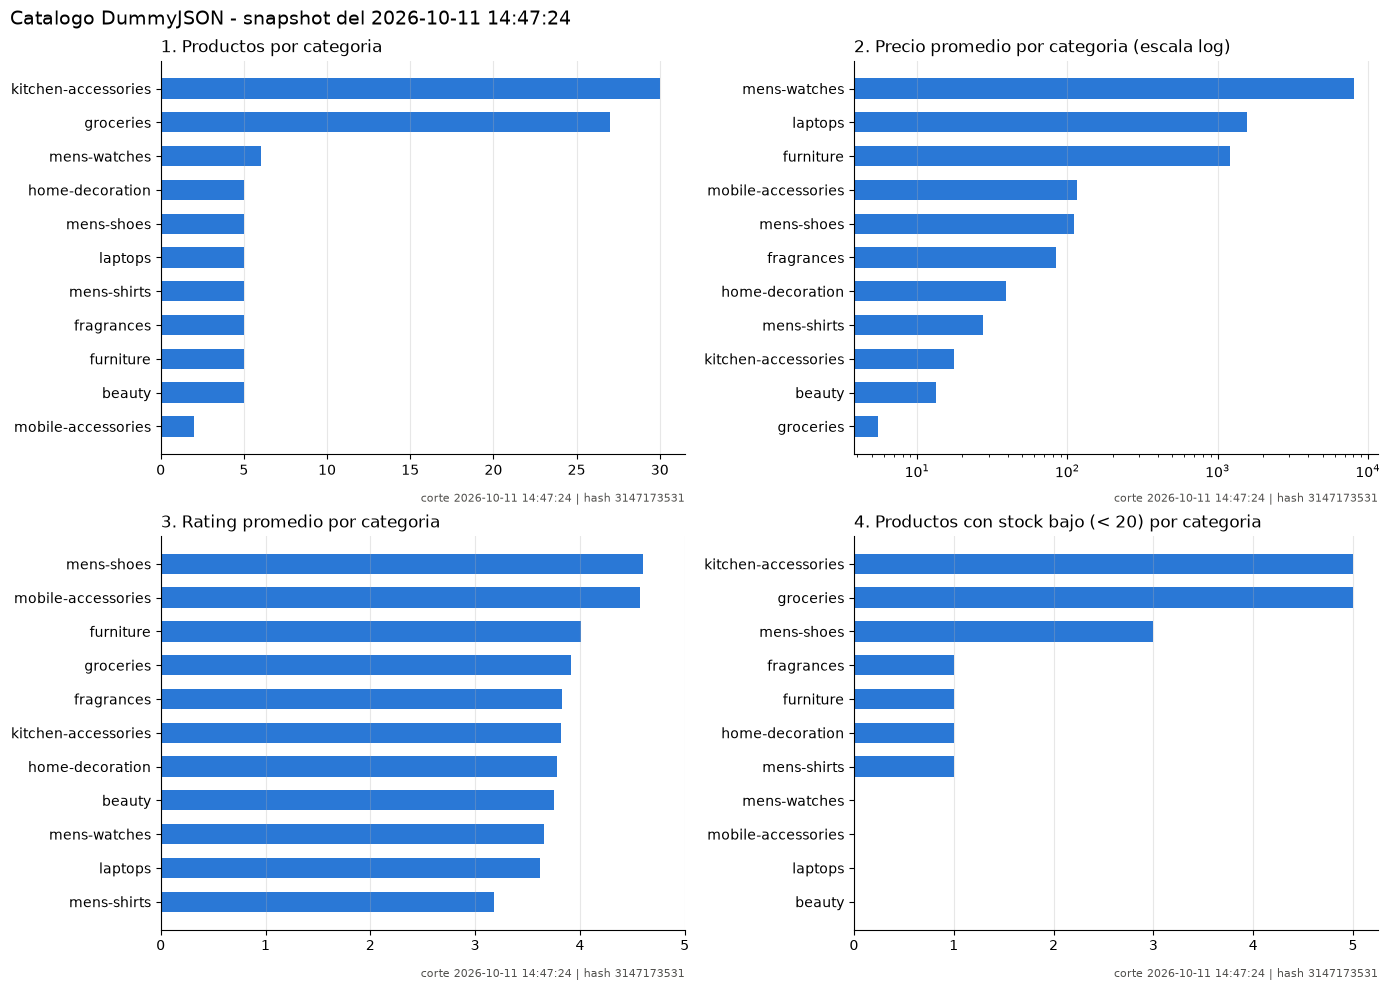

A1 'groceries es la categoria mas barata en promedio': True -> [{'category': 'groceries', 'precio_prom': 5.47}]
A2 'los productos con rating >= 4 tienen mas descuento': False -> [{'rating_alto': 0, 'desc_prom': 10.02}, {'rating_alto': 1, 'desc_prom': 9.15}]


In [11]:
# ESPACIO DE TRABAJO PARA TU PROYECTO FINAL

# === MENSAJE CENTRAL + FIRMA (timestamp y hash) ===
firma = f"corte {mi_timestamp} | hash {mi_hash}"
print("Informe: el catalogo de la tienda es barato en volumen y caro en pocas categorias")
print("Firma:", firma)

# === DESCRIPCION DEL PIPELINE ===
conn = sqlite3.connect("almacen_vivo.db")
n_snap = pd.read_sql("SELECT COUNT(*) AS n FROM snapshot_catalogo", conn)["n"][0]
print(f"Pipeline: API DummyJSON ({fuente}) -> DataFrame de columnas planas + precio_final "
      f"-> SQLite almacen_vivo.db, tabla snapshot_catalogo ({n_snap} filas)")

# === VISUALIZACIONES 1 a 4 (cada una desde una consulta SQL al almacen) ===
consultas = {
    "1. Productos por categoria":
        "SELECT category, COUNT(*) AS valor FROM snapshot_catalogo GROUP BY category",
    "2. Precio promedio por categoria (escala log)":
        "SELECT category, AVG(price) AS valor FROM snapshot_catalogo GROUP BY category",
    "3. Rating promedio por categoria":
        "SELECT category, AVG(rating) AS valor FROM snapshot_catalogo GROUP BY category",
    "4. Productos con stock bajo (< 20) por categoria":
        "SELECT category, SUM(stock < 20) AS valor FROM snapshot_catalogo GROUP BY category",
}
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (titulo, sql) in zip(axes.flat, consultas.items()):
    res = pd.read_sql(sql, conn).sort_values("valor")
    ax.barh(res["category"], res["valor"], color="#2a78d6", height=0.6)
    ax.set_title(titulo, loc="left")
    ax.grid(axis="x", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.text(1, -0.12, firma, transform=ax.transAxes, ha="right", fontsize=8, color="#52514e")
axes[0, 1].set_xscale("log")
axes[1, 0].set_xlim(0, 5)
fig.suptitle("Catalogo DummyJSON - snapshot del " + mi_timestamp, x=0.01, ha="left", fontsize=14)
plt.tight_layout(); plt.show()

# === AFIRMACIONES VALIDADAS CON SQL ===
a1 = pd.read_sql("""SELECT category, ROUND(AVG(price), 2) AS precio_prom FROM snapshot_catalogo
                    GROUP BY category ORDER BY precio_prom LIMIT 1""", conn)
print("A1 'groceries es la categoria mas barata en promedio':",
      a1["category"][0] == "groceries", "->", a1.to_dict("records"))
a2 = pd.read_sql("""SELECT rating >= 4 AS rating_alto, ROUND(AVG(discountPercentage), 2) AS desc_prom
                    FROM snapshot_catalogo GROUP BY rating_alto""", conn)
print("A2 'los productos con rating >= 4 tienen mas descuento':",
      a2["desc_prom"][1] > a2["desc_prom"][0], "->", a2.to_dict("records"))
conn.close()

> **31.** Escribe el título, el mensaje central y TU FIRMA (marca de tiempo + hash).

**Respuesta:** **Catálogo de la tienda: mucho volumen barato y el valor concentrado en pocas categorías.** El 57% de los productos (kitchen-accessories y groceries) cuesta en promedio menos de 18, mientras que relojes, laptops y muebles (16 productos) concentran los precios altos. Firma: corte **2026-10-11 14:47:24**, hash **3147173531**.

> **32.** Describe tu pipeline y cuántos productos extrajiste en tu corte.

**Respuesta:** Extraigo 100 de los 194 productos de la API de DummyJSON, me quedo con las columnas planas, calculo precio_final, agrego fecha_snapshot y hash_extraccion, y cargo todo a SQLite (almacen_vivo.db, tabla snapshot_catalogo). Mi corte tiene 100 productos.

> **33.** Lista tus 4 visualizaciones y la consulta SQL de cada una.

**Respuesta:**

1. **Productos por categoría**: `SELECT category, COUNT(*) FROM snapshot_catalogo GROUP BY category`. Muestra dónde está el volumen: kitchen-accessories (30) y groceries (27) son más de la mitad del catálogo.
2. **Precio promedio por categoría** (escala log, porque va de 5.47 a 8,098.32): `SELECT category, AVG(price) FROM snapshot_catalogo GROUP BY category`. Groceries es la más barata y mens-watches la más cara.
3. **Rating promedio por categoría**: `SELECT category, AVG(rating) FROM snapshot_catalogo GROUP BY category`. mens-shoes es la mejor calificada (4.60) y mens-shirts la peor (3.18).
4. **Productos con stock bajo (< 20)**: `SELECT category, SUM(stock < 20) FROM snapshot_catalogo GROUP BY category`. Hay 17 en total: 5 en kitchen-accessories, 5 en groceries y 3 en mens-shoes.

Afirmaciones validadas con SQL: "groceries es la categoría más barata" es **verdadera** (5.47 en promedio); "los productos con rating de 4 o más tienen más descuento" es **falsa** (9.15% contra 10.02%).

> **34.** ¿Cuál es tu hallazgo más interesante EN TU CORTE de datos?

**Respuesta:** mens-shoes tiene el mejor rating promedio (4.60), pero 3 de sus 5 productos tienen menos de 20 unidades en stock: lo mejor calificado es justo lo que está por agotarse.

> **35.** Escribe tu decisión de arquitectura justificada para una tienda con datos vivos.

**Respuesta:** Un pipeline batch cada hora para el catálogo, que guarde snapshots en modo append (con fecha y hash) en un almacén con esquema estrella, y streaming solo para descontar stock y lanzar alertas. Una hora basta para los precios, el append da el historial y el streaming se reserva para lo que no tolera retraso.

> **36.** Escribe tu conclusión accionable, reconociendo que es válida para tu momento de extracción.

**Respuesta:** Con base en el corte del 2026-10-11 14:47:24: reabastecer primero mens-shoes (mejor rating y 3 de 5 con stock bajo) y después kitchen-accessories y groceries (5 productos con stock bajo cada una). Tampoco conviene subir descuentos para mejorar ratings: los productos con rating de 4 o más tienen menos descuento (9.15% contra 10.02%). Es válido para este corte; hay que revisarlo con el siguiente snapshot.

---
# FASE 5 — Metacognición: por qué esto no lo hace una IA por ti

> **37.** Tu informe lleva una marca de tiempo y un hash únicos de TU extracción. ¿Por qué una IA no podría generar un informe con TU firma temporal exacta?

**Respuesta:** Porque el timestamp y el hash salen de ejecutar la extracción en un momento concreto; una IA no corrió mi código en ese segundo ni recibió mis datos.

> **38.** Si le pidieras a una IA "analiza los productos de DummyJSON", ¿podría saber qué datos exactos recibiste TÚ en TU segundo de ejecución? Explica.

**Respuesta:** No. Puede suponer qué devuelve la API en general, pero no lo que yo recibí en mi segundo exacto; eso solo lo certifica el hash de mi ejecución.

> **39.** Menciona TRES elementos de tu trabajo que dependen de TU momento de ejecución y que una IA no puede reproducir (timestamp, hash, tu corte de datos, tus tiempos medidos...).

**Respuesta:** Mi timestamp (14:47:24), mi hash (3147173531) y mis tiempos medidos (0.0334 s contra 0.0366 s). También el total de Open Food Facts en mi consulta (4,807,198).

> **40.** Una IA puede escribir código para consumir una API, pero ¿puede DECIDIR con qué frecuencia programar el pipeline de TiendaViva, o qué hacer si la fuente cambia de formato? Explica por qué eso requiere tu criterio.

**Respuesta:** Puede escribir el código, pero la frecuencia y qué hacer ante un cambio de formato dependen del negocio de TiendaViva: cuánto cuesta un precio desactualizado, el presupuesto, los límites de la API y qué tan grave es detener una carga. Eso es criterio, no sintaxis.

> **41.** ¿Qué afirmación "que sonaba lógica" resultó depender del contexto o de la fuente en esta actividad? ¿Cómo lo descubriste?

**Respuesta:** La 3 ("el esquema estrella siempre es más rápido"): lo descubrí al medir, porque con 100 filas la estrella fue más lenta. También la 1, que solo fue verdadera porque DummyJSON es estática.

> **42.** Trabajar con datos vivos añade el reto de la REPRODUCIBILIDAD (mismo análisis, distinto resultado según cuándo se corre). ¿Cómo lo resolviste? (Snapshots, fechas, hash.)

**Respuesta:** Guardando cada extracción como snapshot en SQLite con fecha_snapshot y hash_extraccion: el análisis se repite sobre el snapshot y no sobre la API, y el hash indica si los datos cambiaron.

> **43.** ¿Por qué es responsabilidad profesional documentar la fecha de extracción y la fuente en cualquier análisis sobre datos que cambian? Piensa en quién audita tu trabajo después.

**Respuesta:** Porque quien audite o repita el análisis necesita saber de dónde y cuándo salieron los datos. Sin eso no puede verificar los números ni explicar diferencias, y las decisiones tomadas pierden respaldo.

> **44.** Compara: en la actividad anterior el pipeline consumía un CSV fijo; aquí consume fuentes vivas. ¿Cuál se parece más al trabajo real de un ingeniero de datos y por qué?

**Respuesta:** El de fuentes vivas: en el trabajo real los datos llegan de APIs y bases que cambian, fallan y cambian de formato. Un CSV fijo es un caso ideal para practicar.

> **45.** ¿Cómo validarías que tu pipeline sigue funcionando si lo dejas corriendo cada día durante un mes y la fuente externa cambia sin avisar? Propón una rutina de monitoreo.

**Respuesta:** (1) Registrar cada corrida: fecha, filas, hash y errores. (2) Validar esquema y rangos en cada carga. (3) Alertar si cambian las columnas, si el número de filas varía más de cierto porcentaje o si la extracción falla. (4) Revisar a diario un tablero con esos indicadores.

> **46.** Un profesor podría pedirle a una IA que resuelva esta actividad. ¿Por qué la IA fallaría en las preguntas que piden TU firma temporal, TU corte de datos o decisiones para TiendaViva?

**Respuesta:** Porque esas respuestas no son conocimiento general: dependen de mi ejecución (timestamp, hash, datos recibidos, tiempos medidos) o de decisiones justificadas para un caso concreto. La IA tendría que inventarlas.

> **47.** Resume en 3 puntos qué hace robusto a un pipeline que consume fuentes vivas.

**Respuesta:** (1) Manejo de errores y reintentos, para que una fuente caída no rompa todo. (2) Validación de esquema y calidad en cada carga. (3) Snapshots con fecha y hash para poder reproducir y auditar.

> **48.** ¿Qué diferencia hay entre una fuente de DEMOSTRACIÓN (DummyJSON, estable) y una fuente VIVA real (Open Food Facts, que crece)? ¿Cómo afecta esto a la reproducibilidad de un análisis?

**Respuesta:** La de demostración no cambia (mismo hash en consultas repetidas), así que el análisis se reproduce volviendo a consultar. La viva cambia (el total de Open Food Facts subió en segundos), así que solo se reproduce guardando el snapshot con su fecha.

> **49.** Conecta las semanas: limpieza (S4), transformación (S4), visualización (S5), ingeniería de datos con fuentes vivas (S6). ¿Cómo encajan en el proceso completo de ciencia de datos?

**Respuesta:** S6 obtiene los datos (pipelines y almacén), S4 los limpia y transforma, y S5 los comunica con visualizaciones. Juntas forman el ciclo completo (obtener → preparar → analizar → comunicar), y S6 lo vuelve repetible con datos que cambian.

> **50 (reflexión final).** En tu futuro profesional, tendrás que construir sistemas que consuman datos que cambian (precios, clima, transporte, redes sociales). Describe un proyecto concreto donde aplicarías TODO lo de esta actividad. ¿Qué arquitectura elegirías y cómo manejarías que los datos sean vivos?

**Respuesta:** Un monitor de precios de la canasta básica en varias tiendas en línea. Extraería los precios de sus APIs cada 6 horas (batch con reintentos), validaría esquema y rangos, y guardaría cada corte con fecha y hash en un esquema estrella (fact_precios + dim_producto, dim_tienda, dim_tiempo). Encima, un dashboard de tendencias y una alerta cuando un precio suba más de 10%. Lo vivo lo manejaría con snapshots en modo append y la fecha de extracción en cada fila.

---
## Cierre y entrega

Fuiste más allá de "escribir un ETL": **consumiste fuentes vivas**, **firmaste tu extracción con marca de tiempo y hash**, **validaste afirmaciones con evidencia de TU corte**, **diseñaste arquitectura para datos que cambian** y **construiste un informe irrepetible** — algo que ninguna IA puede hacer sin ejecutar en TU momento y con TU criterio. Eso es ser un ingeniero de datos.

### Entrega en Google Classroom

1. Verifica que **todas las celdas corran sin error**.
2. Confirma que respondiste las **50 preguntas** y los **3 retos**.
3. Adjunta tu **informe final firmado** (con marca de tiempo y hash) y tu **pipeline documentado**.
4. **Archivo → Guardar una copia en Drive** y comparte el enlace en Classroom.

### Rúbrica

| Criterio | Puntos |
|---|---|
| Captura y firma de tu extracción (timestamp + hash) | 10 |
| Validación crítica de afirmaciones (Fase 2) | 15 |
| Decisiones de arquitectura justificadas (Fase 3) | 15 |
| Pipeline robusto sobre fuente viva (Fase 4) | 15 |
| Respuestas a las 50 preguntas | 15 |
| **Proyecto final: informe firmado desde datos vivos** | 30 |
| **Total** | **100** |

---
*Universidad de Especialidades UNE · Plantel Centro · Optativa III: Ciencia de Datos*
*Fuentes vivas: DummyJSON y Open Food Facts. Actividad diseñada para el razonamiento propio sobre datos que cambian.*